# W&B results of the embedding experiment (KAN-99)
Gözde Nur Özdemir · ELIZA · Sprint 2

`src/embedding.ipynb` logs everything in its W&B run (step 12): the chosen settings, the scores, every table, a chart for every step and one PDF with all charts. This notebook opens that run, shows the charts and downloads the PDF.

**How to run:** in Colab, *Runtime → Run all* (a CPU is enough, about 1 minute). It asks for your W&B key.

In [1]:
%pip -q install wandb

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gozdenur104 (gozdenur104-metu-middle-east-technical-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Run: E1-retrieval-val-k8 https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/v7g5hhxh
Chosen: {'bm25_remove': 'stopwords + jury', 'dense_weight': 0.8, 'embedding_model': 'BAAI/bge-m3', 'remove_before_embedding': 'none', 'top_k': 8}
{'final/Capped recall@5': 0.47, 'final/Capped recall@8': 0.61, 'final/MRR': 0.61, 'final/Precision@5': 0.24, 'final/Precision@8': 0.2, 'final/Recall@5': 0.43, 'final/Recall@8': 0.59}


wandb:   1 of 1 files downloaded.  


PDF: wandb_pdf/embedding-results.pdf


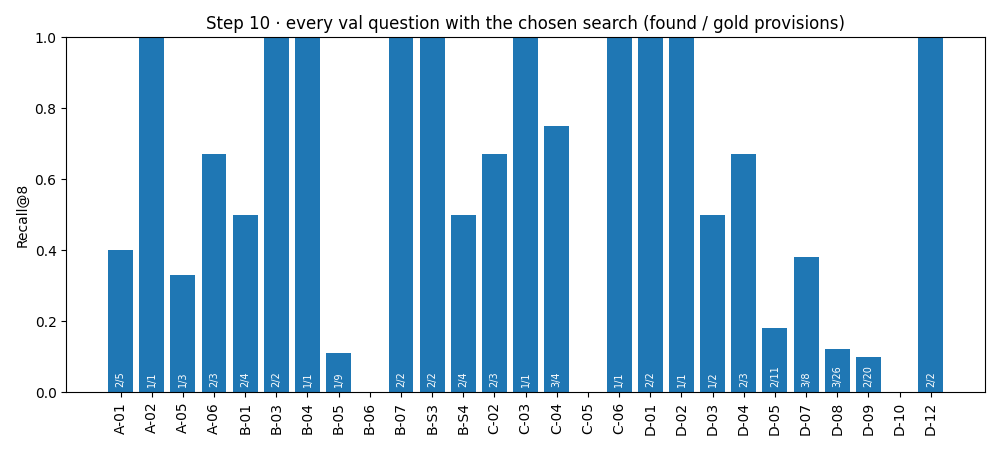

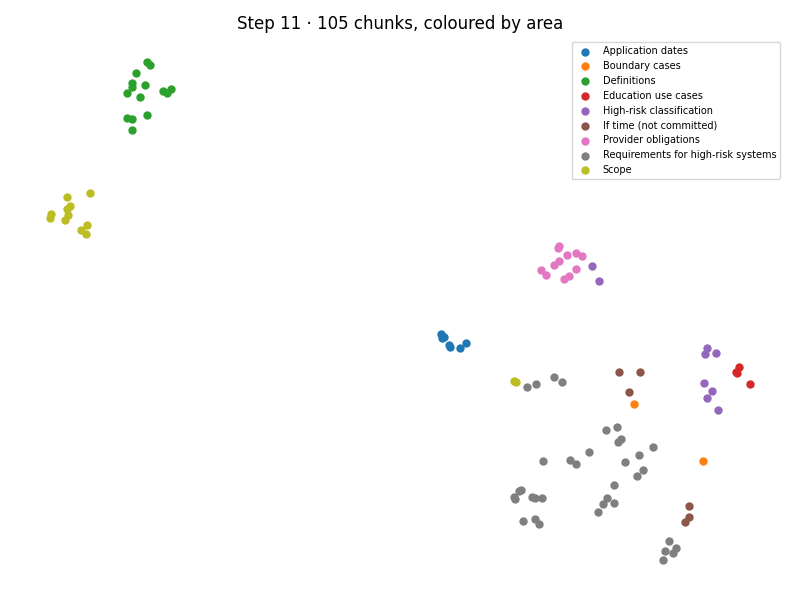

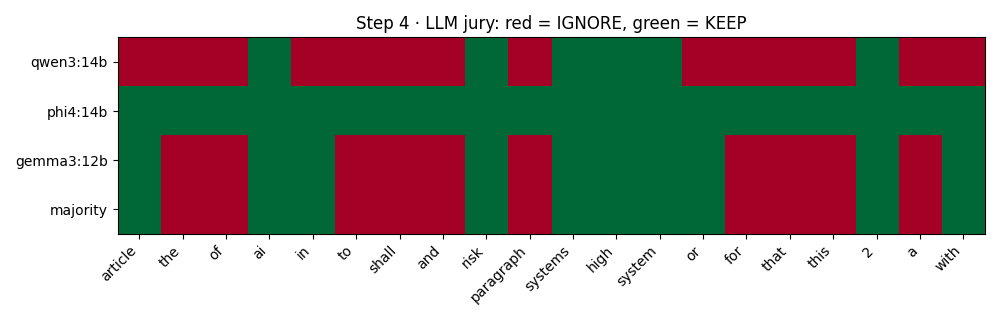

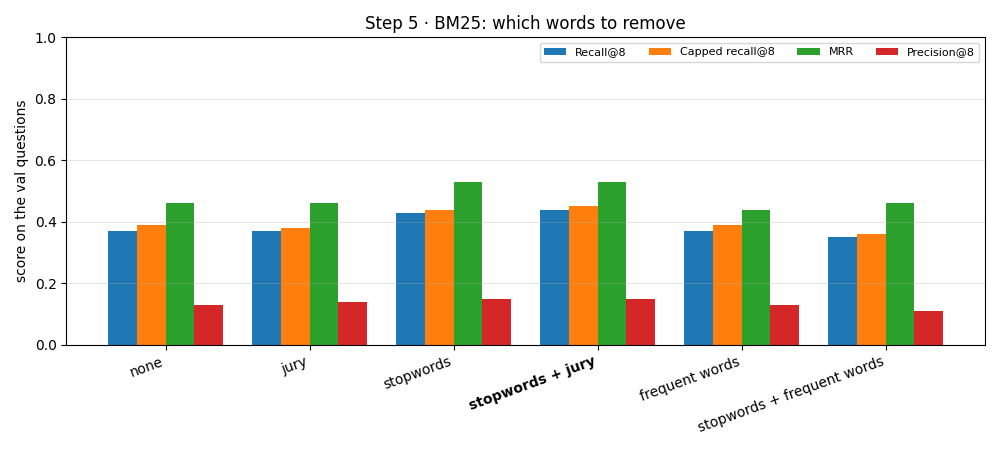

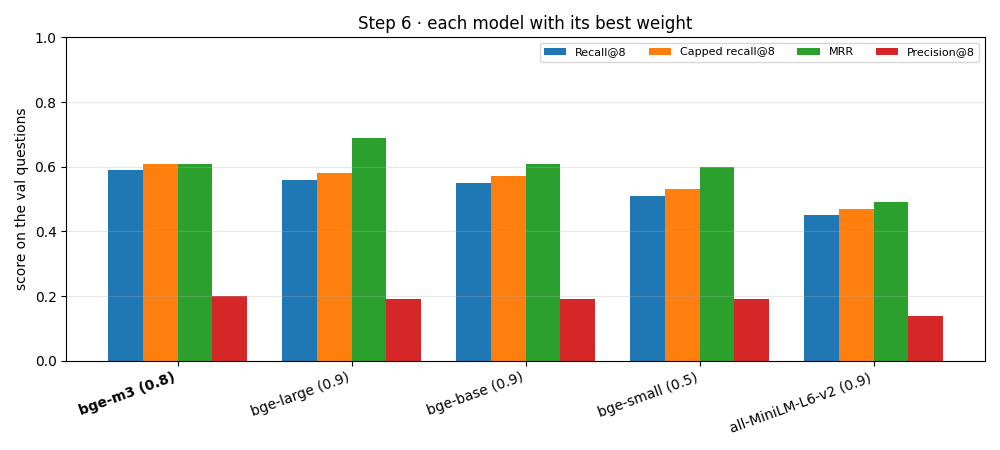

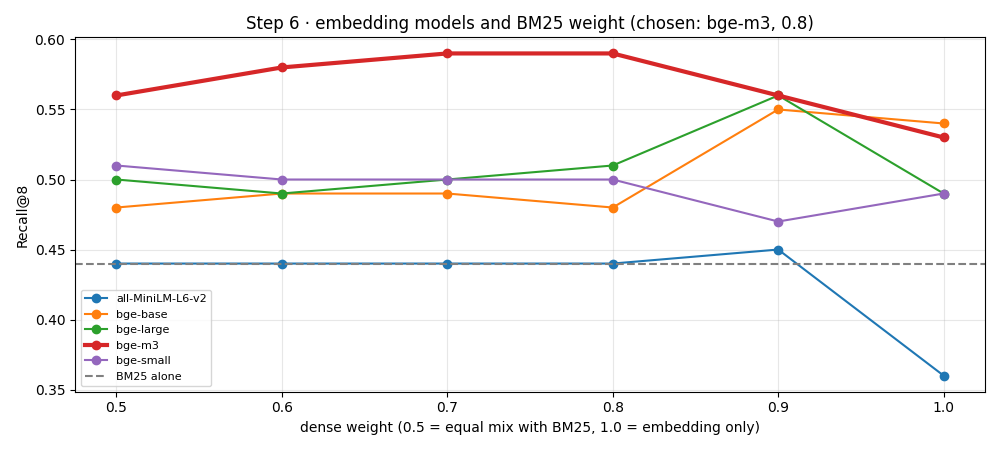

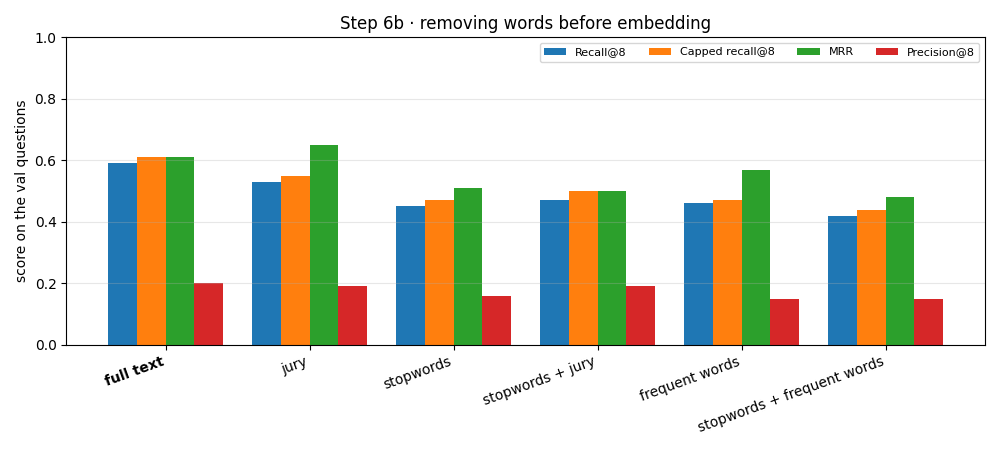

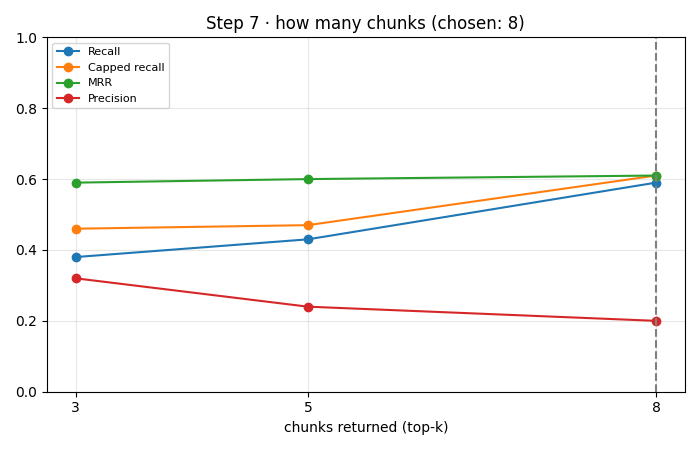

In [2]:
import os, glob, wandb
from IPython.display import Image, display

ENTITY, PROJECT, RUN_ID = "gozdenur104-metu-middle-east-technical-university", "eliza-rag", "v7g5hhxh"
wandb.login()
api = wandb.Api()
run = api.run(f"{ENTITY}/{PROJECT}/{RUN_ID}")
print("Run:", run.name, run.url)

# the chosen settings and the final scores of the run
chosen = run.config["chosen"]
print("Chosen:", chosen)
print({k: round(v, 2) for k, v in sorted(run.summary.items()) if k.startswith("final/")})

# the PDF with every chart (logged by step 12 of src/embedding.ipynb)
report = next(a for a in run.logged_artifacts() if a.type == "report")
folder = report.download("wandb_pdf")
pdf = glob.glob(os.path.join(folder, "*.pdf"))[0]
print("PDF:", pdf)

# the charts, one by one
for f in run.files():
    if f.name.startswith("media/images/charts/"):
        display(Image(f.download("wandb_charts", replace=True).name))

In [3]:

try:
    from google.colab import files
    files.download(pdf)
except ImportError:
    print("Saved:", pdf)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>